## Historical Billboard Hot 100 trends and returns

This notebook describes chart persistence, repeat entries, and changes across broad historical periods. It uses the cleaned Billboard data and leaves the original file unchanged.

### Definitions and limits

A chart run is a continuous sequence of weekly records for the same song and artist, allowing at most seven days between chart dates. A return is a later run after a gap greater than seven days. This is a practical dataset-based definition; it does not distinguish a true commercial comeback from chart-recording gaps or changes in title/artist credit.

The data does not include release dates. “Song age” therefore means time since first observed Hot 100 appearance only when explicitly used as a proxy, not time since release. Period comparisons count chart records within each period; songs crossing period boundaries are truncated, and the latest period is right-censored.

##### Load and prepare the Billboard data

In [22]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = Path('../data/cleaned/billboard_cleaned.csv')
billboard = pd.read_csv(DATA_PATH, parse_dates=['date'], low_memory=False)

billboard['rank'] = pd.to_numeric(billboard['rank'], errors='coerce')

# Remove rows without the information needed for this analysis.
billboard = billboard.dropna(subset=['date', 'song', 'artist', 'rank']).copy()

# Put each song and artist together in date order before checking chart gaps.
billboard = billboard.sort_values(['song', 'artist', 'date']).reset_index(drop=True)

# Show the size and date coverage of the data we loaded.
print(f'{len(billboard):,} chart rows')
print(f"{billboard['date'].min():%Y-%m-%d} to {billboard['date'].max():%Y-%m-%d}")
print(f"{billboard[['song', 'artist']].drop_duplicates().shape[0]:,} distinct song/artist credits")

355,758 chart rows
1958-07-30 to 2026-09-30
32,688 distinct song/artist credits


##### Identify continuous chart runs and returns

In [23]:
song_artist = ['song', 'artist']

# number of days since this same song and artist were charted before.
billboard['gap_days'] = billboard.groupby(song_artist)['date'].diff().dt.days

# start a new chart run when this is the first chart record or the gap is over a week.
billboard['starts_new_run'] = billboard['gap_days'].isna() | billboard['gap_days'].gt(7)

# number the chart runs separately for each song and artist.
billboard['run_number'] = billboard.groupby(song_artist)['starts_new_run'].cumsum()

# summarize each run: start/end dates, how many chart dates, and best (lowest) rank.
runs = (billboard.groupby(song_artist + ['run_number'], as_index=False)
        .agg(start_date=('date', 'min'), end_date=('date', 'max'),
             chart_weeks=('date', 'nunique'), best_rank=('rank', 'min')))

# summarize each song/artist credit across its full history.
song_summary = (billboard.groupby(song_artist, as_index=False)
                .agg(first_chart_date=('date', 'min'), last_chart_date=('date', 'max'),
                     chart_weeks=('date', 'nunique'), best_rank=('rank', 'min'),
                     chart_runs=('run_number', 'nunique')))

# A run numbered 2 or higher means the song returned after a gap.
print(f"Distinct song/artist credits: {len(song_summary):,}")
print(f"Credits with multiple runs: {(song_summary['chart_runs'] > 1).sum():,}")
print(f"Later runs after a gap: {(runs['run_number'] > 1).sum():,}")

# Display the ten latest returns so we can inspect real examples.
display(runs[runs['run_number'] > 1].sort_values('start_date').tail(10))

Distinct song/artist credits: 32,688
Credits with multiple runs: 2,784
Later runs after a gap: 3,715


,song,artist,run_number,start_date,end_date,chart_weeks,best_rank
24639,Ran To Atlanta,Drake Featuring Future & Molly Santana,2,2026-09-16,2026-09-16,1,93
18022,Less,Olivia Rodrigo,2,2026-09-16,2026-09-16,1,96
20239,Matadora,Karol G,2,2026-09-16,2026-09-16,1,98
26027,Say So,Dan + Shay,2,2026-09-23,2026-09-30,2,89
5192,California Girls,Future,2,2026-09-23,2026-09-23,1,95
26285,September,"""Earth, Wind & Fire""",2,2026-09-30,2026-09-30,1,45
21518,My Way,Riley Green,3,2026-09-30,2026-09-30,1,60
17456,Kingdom Of Fear,Cameron Whitcomb,5,2026-09-30,2026-09-30,1,100
8320,Dope Girl,Rod Wave,2,2026-09-30,2026-09-30,1,95
19794,Lush Life,Zara Larsson,4,2026-09-30,2026-09-30,1,42


#### Compare broad periods

In [24]:
# each tuple sets a period label and its start and end dates.
periods = [
    ('1958–1992', '1958-01-01', '1992-12-31'),
    ('1993–2008', '1993-01-01', '2008-12-31'),
    ('2009–2019', '2009-01-01', '2019-12-31'),
    ('2020–2026*', '2020-01-01', '2026-12-31'),
]

period_rows = []

for label, start, end in periods:
    # Keep only chart records whose dates fall within this period.
    part = billboard[billboard['date'].between(start, end)]

    # Count chart weeks and find best rank for each song/artist in this period.
    per_song = part.groupby(song_artist).agg(
        chart_weeks=('date', 'nunique'), best_rank=('rank', 'min'))

    # Save a few simple measurements so we can compare the periods.
    period_rows.append({
        'period': label,
        'chart_rows': len(part),
        'distinct_song_artist_credits': len(per_song),
        'median_chart_weeks_in_period': per_song['chart_weeks'].median(),
        'one_week_share': (per_song['chart_weeks'].eq(1).mean() * 100),
        'credits_reaching_top_10': int(per_song['best_rank'].le(10).sum()),
    })

# Turn our saved measurements into a table and display rounded values.
period_summary = pd.DataFrame(period_rows)
display(period_summary.round(1))

,period,chart_rows,distinct_song_artist_credits,median_chart_weeks_in_period,one_week_share,credits_reaching_top_10
0,1958–1992,179658,18306,9.0,3.1,3367
1,1993–2008,83500,5403,16.0,4.1,948
2,2009–2019,57300,5001,8.0,27.1,594
3,2020–2026*,35300,4418,2.0,38.8,434


#### Visualize chart persistence and repeat runs

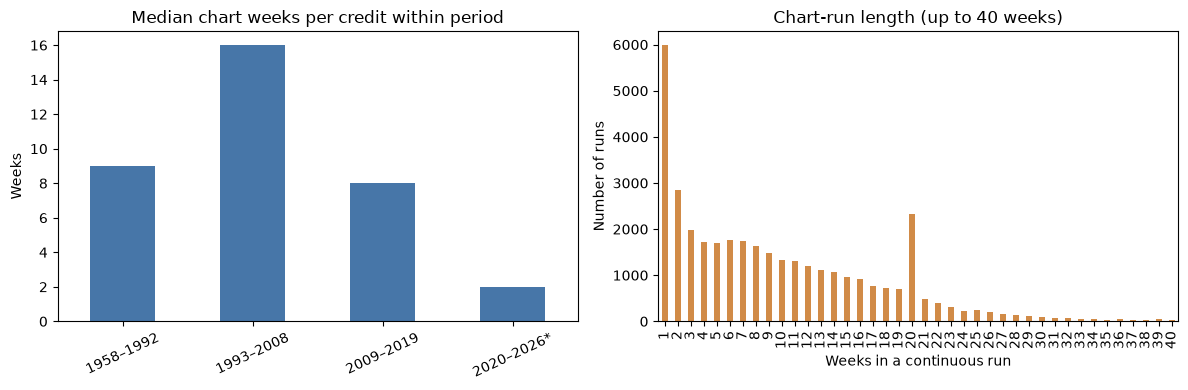

Share of all chart runs longer than 40 weeks: 0.77 %


In [25]:
# Make a chart area with two plots side by side.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Plot the typical (median) number of chart weeks in each historical period.
period_summary.plot(x='period', y='median_chart_weeks_in_period', kind='bar',
                    ax=axes[0], legend=False, color='#4776A8')
axes[0].set_title('Median chart weeks per credit within period')
axes[0].set_ylabel('Weeks')
axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=25)

# Count chart runs of each length, showing lengths up to 40 weeks.
run_counts = runs.groupby('chart_weeks').size().sort_index()
run_counts[run_counts.index <= 40].plot(kind='bar', ax=axes[1], color='#D18B47')
axes[1].set_title('Chart-run length (up to 40 weeks)')
axes[1].set_xlabel('Weeks in a continuous run')
axes[1].set_ylabel('Number of runs')

# Tidy the spacing and show both plots.
plt.tight_layout()
plt.show()

# Calculate how many runs lasted longer than 40 weeks.
long_run_share = (runs['chart_weeks'] > 40).mean() * 100
print('Share of all chart runs longer than 40 weeks:', round(long_run_share, 2), '%')

#### Inspect older songs that returned

This list is a review aid: it shows credits whose later chart run began at least ten years after their first observed appearance. It does not establish release age or identify what caused a return.

In [26]:
# Keep only song/artist credits that have more than one separate chart run.
first_dates = song_summary[song_summary['chart_runs'] > 1][song_artist + ['first_chart_date']]

# Add the first observed chart date to each later run.
return_examples = runs[runs['run_number'] > 1].merge(first_dates, on=song_artist, how='left')

# Estimate years between the first observed chart date and the later return.
# This is not the song's real age because release dates are not in this dataset.
return_examples['years_since_first_observed'] = (
    (return_examples['start_date'] - return_examples['first_chart_date']).dt.days / 365.25)

# Keep returns that are at least ten years after the first chart appearance.
long_gap_returns = return_examples[return_examples['years_since_first_observed'] >= 10]

# Show up to 25 recent examples for a person to review.
display(long_gap_returns.sort_values('start_date', ascending=False)[
    song_artist + ['first_chart_date', 'start_date', 'chart_weeks',
                   'best_rank', 'years_since_first_observed']].head(25))
print('Later runs at least 10 years after first observed chart date:', len(long_gap_returns))

,song,artist,first_chart_date,start_date,chart_weeks,best_rank,years_since_first_observed
2737,September,"""Earth, Wind & Fire""",1978-11-15,2026-09-30,1,45,47.874059
1983,Lush Life,Zara Larsson,2016-07-27,2026-09-30,1,42,10.176591
1607,Islands In The Stream,Kenny Rogers Duet With Dolly Parton,1983-08-24,2026-09-02,1,26,43.025325
125,9 To 5,Dolly Parton,1980-11-26,2026-09-02,2,18,45.765914
1690,Jolene,Dolly Parton,1974-01-23,2026-09-02,3,16,52.607803
1506,I Will Always Love You,Dolly Parton,1982-07-28,2026-09-02,2,27,44.098563
1310,Here You Come Again,Dolly Parton,1977-10-12,2026-09-02,1,44,48.889802
3603,Wonderwall,Oasis,1996-01-24,2026-07-22,3,27,30.491444
2382,Party In The U.S.A.,Miley Cyrus,2009-08-26,2026-07-15,1,25,16.884326
818,Don't Stop Believin',Journey,1981-10-28,2026-07-15,1,35,44.711841


Later runs at least 10 years after first observed chart date: 196


### Preliminary TikTok cross-check

These cells check whether possible long-gap Billboard returns fall within TikTok's date range and whether their normalized titles and artists match. This is an initial name check; it does not compare rankings or show that TikTok caused a return.

In [27]:
# Load TikTok dates so we can find when its rankings are available.
tiktok = pd.read_csv('../data/cleaned/tiktok_7day_cleaned.csv', parse_dates=['date'])
tiktok_start = tiktok['date'].min()
tiktok_end = tiktok['date'].max()

# Keep possible long-gap returns whose return date falls within TikTok's date range.
returns_during_tiktok = long_gap_returns[
    long_gap_returns['start_date'].between(tiktok_start, tiktok_end)
].copy()

# Show how many possible returns overlap with TikTok, and inspect the candidates.
print(f'TikTok date range: {tiktok_start:%Y-%m-%d} to {tiktok_end:%Y-%m-%d}')
print('Possible long-gap returns during this period:', len(returns_during_tiktok))
display(returns_during_tiktok.sort_values('start_date')[
    song_artist + ['first_chart_date', 'start_date', 'chart_weeks',
                   'best_rank', 'years_since_first_observed']
])

TikTok date range: 2024-05-23 to 2025-07-09
Possible long-gap returns during this period: 15


,song,artist,first_chart_date,start_date,chart_weeks,best_rank,years_since_first_observed
515,Bye Bye Bye,*NSYNC,2000-01-26,2024-08-14,1,45,24.550308
1103,Ghostbusters,Ray Parker Jr.,1984-06-13,2024-11-06,1,28,40.399726
2102,Monster Mash,"Bobby ""Boris"" Pickett And The Crypt-Kickers",1962-09-05,2024-11-06,1,30,62.171116
2883,Somebody's Watching Me,Rockwell,1984-01-25,2024-11-06,1,50,40.783025
3221,Thriller,Michael Jackson,1984-02-08,2024-11-06,1,20,40.744695
202,All I Want For Christmas Is You,Mariah Carey,2000-01-05,2024-11-27,6,1,24.895277
2593,Rockin' Around The Christmas Tree,Brenda Lee,1960-12-07,2024-11-27,6,2,63.972621
1676,Jingle Bell Rock,Bobby Helms,1958-12-17,2024-12-04,5,3,65.965777
3102,The Christmas Song (Merry Christmas To You),"Nat ""King"" Cole",1960-12-07,2024-12-04,5,10,63.991786
3321,Underneath The Tree,Kelly Clarkson,2013-12-18,2024-12-04,5,9,10.962355


In [28]:
# Make names easier to compare by ignoring capitalization, spaces, and punctuation.
# For example, "Run Rudolph Run" and "Run, Rudolph Run" become the same key.
def normalize_text(value):
    return ''.join(character for character in str(value).casefold() if character.isalnum())

# Create comparison keys for the Billboard return candidates.
returns_during_tiktok['title_key'] = returns_during_tiktok['song'].map(normalize_text)
returns_during_tiktok['artist_key'] = returns_during_tiktok['artist'].map(normalize_text)

# Create the same keys for TikTok songs, keeping each distinct song ID/name once.
tiktok_song_names = tiktok[['song_id', 'music_title', 'music_author']].drop_duplicates().copy()
tiktok_song_names['title_key'] = tiktok_song_names['music_title'].map(normalize_text)
tiktok_song_names['artist_key'] = tiktok_song_names['music_author'].map(normalize_text)

# Keep only candidates where both the cleaned title and artist match exactly.
tiktok_return_matches = returns_during_tiktok.merge(
    tiktok_song_names,
    on=['title_key', 'artist_key'],
    how='inner'
)

# Count distinct Billboard returns matched, and distinct TikTok song IDs.
matched_returns = tiktok_return_matches[['song', 'artist', 'start_date']].drop_duplicates()
print('Possible returns:', len(returns_during_tiktok))
print('Returns with an exact TikTok title and artist match:', len(matched_returns))
print('TikTok song IDs found:', tiktok_return_matches['song_id'].nunique())

# Display the names side by side so we can review the matches.
display(tiktok_return_matches[
    ['song', 'artist', 'start_date', 'music_title', 'music_author', 'song_id']
].drop_duplicates().sort_values('song'))

Possible returns: 15
Returns with an exact TikTok title and artist match: 7
TikTok song IDs found: 9


,song,artist,start_date,music_title,music_author,song_id
0,All I Want For Christmas Is You,Mariah Carey,2024-11-27,All I Want for Christmas Is You,Mariah Carey,6696407973742266369
1,All I Want For Christmas Is You,Mariah Carey,2024-11-27,All I Want for Christmas Is You,Mariah Carey,6751820041638905857
2,Bye Bye Bye,*NSYNC,2024-08-14,Bye Bye Bye,*NSYNC,6696408154692913153
3,Ghostbusters,Ray Parker Jr.,2024-11-06,Ghostbusters,Ray Parker Jr.,6750397545127610370
4,Jingle Bell Rock,Bobby Helms,2024-12-04,Jingle Bell Rock,Bobby Helms,6732301558127527938
5,Rockin' Around The Christmas Tree,Brenda Lee,2024-11-27,Rockin' Around The Christmas Tree,Brenda Lee,6732342110835443714
6,Run Rudolph Run,Chuck Berry,2024-12-11,"Run, Rudolph Run",Chuck Berry,6951751180292720642
7,Run Rudolph Run,Chuck Berry,2024-12-11,Run Rudolph Run,Chuck Berry,7161482870979037185
8,Somebody's Watching Me,Rockwell,2024-11-06,Somebody's Watching Me,Rockwell,6732353660514224130
